# Entrenamiento XGBoost: pronóstico mensual de incidentes por parroquia

## Contexto y objetivo

Este análisis estudia los registros de incidentes del Ecuador para estimar cuántos se reportan por parroquia y mes. El propósito es reconocer patrones estacionales y territoriales que ayuden a priorizar la planificación y la comunicación preventiva a turistas.

La unidad de análisis será **una parroquia en un mes** y el objetivo será el **número de incidentes reportados** (`target_count`). Por tanto, se trata de un problema de regresión de conteos, no de clasificación del mes de un incidente individual. Los meses sin registros dentro del período cubierto se representan con cero.

**Alcance y cautelas:** los registros describen incidentes reportados, no el riesgo real de victimización. El dataset no incluye población expuesta, flujo de turistas, coordenadas ni una medida de subregistro; las parroquias con más reportes no necesariamente son proporcionalmente más peligrosas. Los resultados no deben presentarse como una evaluación causal ni como una alerta de seguridad por sí solos.

El CSV tiene aproximadamente 2.33 GB y 17.68 millones de filas. El código lo lee por bloques y conserva solo columnas necesarias; no exporta modelos, tablas ni archivos auxiliares.

## 1. Estrategia de entrenamiento

- Agregar los registros por provincia, cantón, parroquia, año y mes. No usar `Subtipo`, `Servicio`, `Dia_Semana` ni `Dias_Desde_Inicio` como predictores: describen incidentes ya observados o revelan información que no está necesariamente disponible al emitir un pronóstico mensual.
- Crear un panel mensual por parroquia dentro de la cobertura observada, completando con cero las combinaciones sin reportes. No asumir meses anteriores a julio de 2021 ni posteriores a agosto de 2026 como ceros observados.
- Usar estacionalidad cíclica, tendencia, conteos rezagados (1, 3 y 12 meses) y promedios históricos recientes. Los rezagos se calculan exclusivamente con meses previos.
- Separar cronológicamente: entrenamiento hasta 2023, validación en 2024 para parada temprana y prueba final en los doce meses completos de 2025. El año 2026 es parcial y queda fuera de la evaluación principal.
- Comparar XGBoost con dos referencias simples: último mismo mes del año anterior y promedio histórico de la misma parroquia y mes. La evaluación es un pronóstico mensual actualizado: para cada mes se supone conocido el conteo real hasta el mes anterior.
- Reportar errores en la unidad de incidentes por parroquia-mes, además del ajuste agregado. No interpretar el R² aislado como medida suficiente de utilidad.

In [1]:
# Importamos las librerías de análisis, visualización y modelado.
from pathlib import Path
from collections import Counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_poisson_deviance
from xgboost import XGBRegressor

# Configuramos gráficos reproducibles y de lectura clara.
RANDOM_STATE = 42
CHUNK_SIZE = 250_000
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

# Buscamos primero la ruta indicada para este proyecto y luego una ruta relativa al notebook.
DATASET_PATH = Path('data/processed/dataset_proyecto_preparado.csv')
if not DATASET_PATH.exists():
    relative_candidates = [
        Path.cwd() / 'data' / 'processed' / 'dataset_proyecto_preparado.csv',
        Path.cwd().parent / 'data' / 'processed' / 'dataset_proyecto_preparado.csv',
    ]
    DATASET_PATH = next((candidate for candidate in relative_candidates if candidate.exists()), DATASET_PATH)

# Detenemos el análisis con un mensaje útil si el archivo no está en una ruta conocida.
if not DATASET_PATH.exists():
    raise FileNotFoundError(f'No se encontró el CSV. Ajuste DATASET_PATH. Ruta revisada: {DATASET_PATH}')

print(f'Archivo: {DATASET_PATH}')
print(f'Tamaño: {DATASET_PATH.stat().st_size / (1024**3):.2f} GB')

Archivo: c:\Users\PAULA\Documents\IntegradorG3\data\processed\dataset_proyecto_preparado.csv
Tamaño: 2.17 GB


## 2. Lectura por bloques y agregación

Se conservan las columnas geográficas y temporales para construir la serie de conteos. También se revisan `Servicio` y `Subtipo` como diagnóstico, pero se excluyen del modelo porque no son predictores disponibles antes de que ocurra el incidente. Los identificadores geográficos se leen como texto para tolerar valores como `SIN DATO`.

In [2]:
# Definimos columnas para el diagnóstico y la agregación mensual.
GEO_COLUMNS = ['provincia', 'Canton', 'Parroquia']
READ_COLUMNS = GEO_COLUMNS + ['Cod_Parroquia', 'Mes', 'Anio', 'Servicio', 'Subtipo']
TEXT_COLUMNS = GEO_COLUMNS + ['Cod_Parroquia', 'Servicio', 'Subtipo']

# Inicializamos acumuladores pequeños; no guardamos en memoria las 17.7 millones de filas.
partial_aggregates = []
missing_counts = Counter()
category_counts = {column: Counter() for column in TEXT_COLUMNS}
year_month_counts = Counter()
total_rows = 0
invalid_period_rows = 0

# Procesamos el CSV en bloques y sumamos conteos por parroquia, año y mes.
for chunk in pd.read_csv(
    DATASET_PATH,
    usecols=READ_COLUMNS,
    chunksize=CHUNK_SIZE,
    encoding='utf-8-sig',
    low_memory=False,
    dtype={column: 'string' for column in TEXT_COLUMNS},
):
    total_rows += len(chunk)
    missing_counts.update(chunk.isna().sum().to_dict())

    # Normalizamos etiquetas vacías y espacios para no multiplicar categorías equivalentes.
    for column in GEO_COLUMNS:
        chunk[column] = chunk[column].fillna('SIN DATO').str.strip().replace('', 'SIN DATO')

    # Contamos las categorías para describir el dataset sin usarlas como predictores.
    for column in TEXT_COLUMNS:
        category_counts[column].update(
            chunk[column].fillna('SIN DATO').astype(str).value_counts().to_dict()
        )

    # Validamos que el año y el mes puedan utilizarse como período calendario.
    chunk['Anio'] = pd.to_numeric(chunk['Anio'], errors='coerce')
    chunk['Mes'] = pd.to_numeric(chunk['Mes'], errors='coerce')
    valid_period = chunk['Anio'].notna() & chunk['Mes'].between(1, 12)
    invalid_period_rows += int((~valid_period).sum())
    valid_chunk = chunk.loc[valid_period].copy()
    valid_chunk['Anio'] = valid_chunk['Anio'].astype('int16')
    valid_chunk['Mes'] = valid_chunk['Mes'].astype('int8')

    # Guardamos la cobertura global por año y mes para identificar períodos incompletos.
    year_month_counts.update(
        valid_chunk.groupby(['Anio', 'Mes'], observed=True).size().to_dict()
    )

    # Reducimos cada bloque antes de conservarlo para limitar el uso de memoria.
    partial = (
        valid_chunk.groupby(GEO_COLUMNS + ['Anio', 'Mes'], observed=True, dropna=False)
        .size()
        .rename('target_count')
        .reset_index()
    )
    partial_aggregates.append(partial)

# Combinamos los conteos parciales y obtenemos una sola fila por parroquia-mes.
monthly_observations = (
    pd.concat(partial_aggregates, ignore_index=True)
    .groupby(GEO_COLUMNS + ['Anio', 'Mes'], as_index=False, observed=True)['target_count']
    .sum()
)

print(f'Filas leídas: {total_rows:,}')
print(f'Filas sin año/mes válido excluidas: {invalid_period_rows:,}')
print(f'Combinaciones parroquia-año-mes con incidentes: {len(monthly_observations):,}')
print(f'Tamaño de la tabla agregada en memoria: {monthly_observations.memory_usage(deep=True).sum() / (1024**2):.1f} MB')

Filas leídas: 17,680,253
Filas sin año/mes válido excluidas: 0
Combinaciones parroquia-año-mes con incidentes: 61,774
Tamaño de la tabla agregada en memoria: 12.0 MB


## 3. Análisis descriptivo y calidad

Las tablas y gráficos siguientes se calculan directamente desde el archivo. La matriz año-mes permite distinguir años completos de los extremos parciales del período; la frecuencia mensual total no debe compararse entre años sin considerar esa cobertura.

,columna,valores_ausentes,categorias_distintas
0,Subtipo,1,691
1,provincia,0,27
2,Cod_Parroquia,0,1043
3,Canton,0,225
4,Parroquia,0,981
5,Servicio,0,8
6,Mes,0,12
7,Anio,0,6


Mes,1,2,3,4,5,6,7,8,9,10,11,12
Anio,,,,,,,,,,,,
2021,0,0,0,0,0,0,314507,319989,307665,327820,299013,334055
2022,304575,294034,312801,311739,318799,291802,309337,296460,294140,306756,287294,302367
2023,286435,270613,289472,289411,291364,290245,295384,284365,287146,289047,273956,299651
2024,208194,276844,291219,271992,278104,277077,268289,269571,279947,294494,279589,297323
2025,267790,244669,277160,263466,277968,271175,268119,275442,267225,266910,269066,289009
2026,267009,250314,282649,268763,290974,268513,260280,280867,0,0,0,0


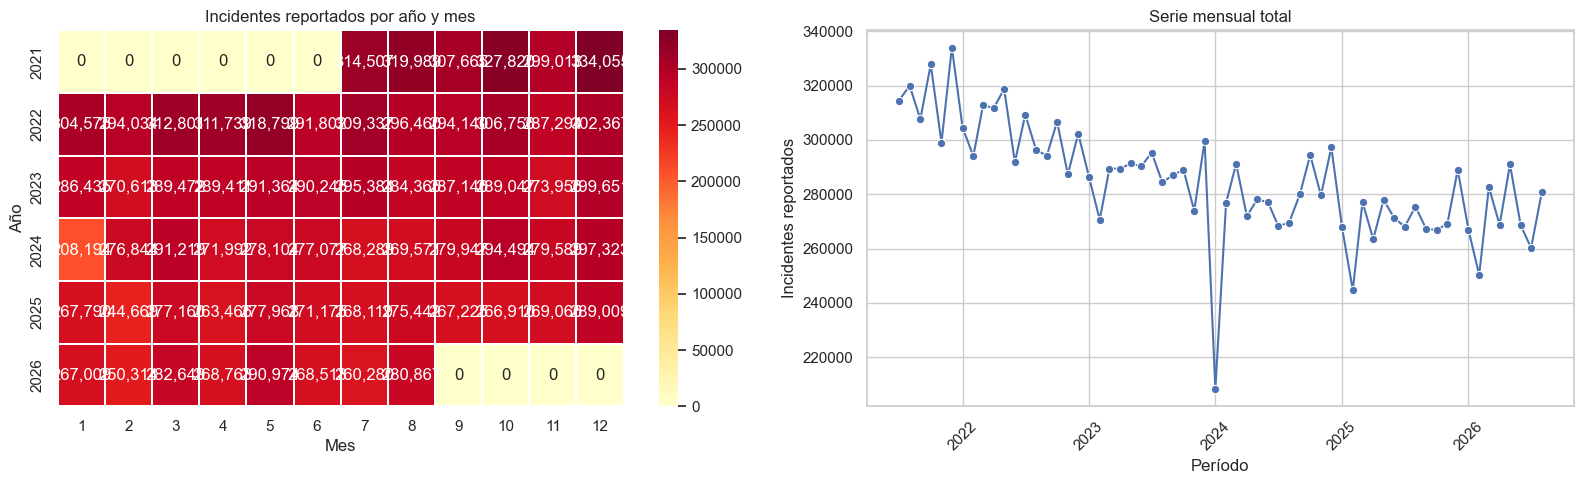

,Servicio,registros
0,SEGURIDAD CIUDADANA,12268977
1,GESTIÓN SANITARIA,2073797
2,TRÁNSITO Y MOVILIDAD,1879422
3,SERVICIOS MUNICIPALES,851552
4,GESTIÓN DE SINIESTROS,305453
5,SERVICIO MILITAR,210828
6,GESTIÓN DE RIESGOS,88003
7,SIN DATO,2221


,Subtipo,registros
0,PATRULLAJE POLICIAL EN EL SECTOR SOLICITADO,4354616
1,LIBADORES,1332668
2,PRESENCIA POLICIAL,941924
3,RESGUARDO A PERSONAS QUE TRASLADA VALORES A NI...,569908
4,ESCÁNDALO EN ESPACIO PÚBLICO,550735
5,PROCEDIMIENTOS,406976
6,REGISTRO DE PERSONAS Y/O VEHÍCULOS CON ACTITUD...,338485
7,FICHA DE DATOS INFORMACIÓN,308604
8,VIOLENCIA CONTRA LA MUJER O MIEMBROS DEL NÚCLE...,274704
9,TRANSPORTE SECUNDARIO,272870


,provincia,Canton,Parroquia,target_count
0,GUAYAS,GUAYAQUIL,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",3015003
1,PICHINCHA,QUITO,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",2940892
2,AZUAY,CUENCA,"CUENCA, CABECERA CANTONAL Y CAPITAL PROVINCIAL.",699387
3,SANTO DOMINGO DE LOS TSACHILAS,SANTO DOMINGO,"SANTO DOMINGO DE LOS COLORADOS, CABECERA CANTO...",503561
4,TUNGURAHUA,AMBATO,"AMBATO, CABECERA CANTONAL Y CAPITAL PROVINCIAL",457988
5,EL ORO,MACHALA,"MACHALA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",374948
6,IMBABURA,IBARRA,"SAN MIGUEL DE IBARRA, CABECERA CANTONAL Y CAPI...",373976
7,CHIMBORAZO,RIOBAMBA,"RIOBAMBA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",355014
8,LOJA,LOJA,"LOJA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",323143
9,GUAYAS,DURAN,"ELOY ALFARO (DURÁN), CABECERA CANTONAL",263057


Cobertura mensual observada: 2021-07 a 2026-08 (62 meses distintos)
Parroquias identificadas por provincia, cantón y nombre: 1,053


In [3]:
# Resumimos faltantes y cardinalidad observados durante la lectura por bloques.
# Resumimos faltantes y cardinalidad; Mes y Anio se cuentan desde los períodos válidos.
distinct_counts = {column: len(category_counts[column]) for column in TEXT_COLUMNS}
distinct_counts['Mes'] = len({month for year, month in year_month_counts})
distinct_counts['Anio'] = len({year for year, month in year_month_counts})

quality_table = pd.DataFrame({
    'columna': list(missing_counts.keys()),
    'valores_ausentes': list(missing_counts.values()),
    'categorias_distintas': [distinct_counts.get(column, 0) for column in missing_counts],
})
display(quality_table.sort_values('valores_ausentes', ascending=False).reset_index(drop=True))

# Construimos una matriz de cobertura y volumen de registros por año y mes.
year_month_table = (
    pd.Series(year_month_counts, name='incidentes')
    .rename_axis(['Anio', 'Mes'])
    .reset_index()
    .pivot(index='Anio', columns='Mes', values='incidentes')
    .reindex(columns=range(1, 13))
    .fillna(0)
    .astype('int64')
)
display(year_month_table)

# Visualizamos el número de reportes por período para reconocer estacionalidad y cobertura parcial.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(year_month_table, cmap='YlOrRd', fmt=',.0f', annot=True, linewidths=0.3, ax=axes[0])
axes[0].set_title('Incidentes reportados por año y mes')
axes[0].set_xlabel('Mes')
axes[0].set_ylabel('Año')

monthly_totals_all = pd.Series(year_month_counts, name='incidentes').rename_axis(['Anio', 'Mes']).reset_index()
monthly_totals_all['period'] = pd.PeriodIndex(
    pd.to_datetime(dict(year=monthly_totals_all['Anio'], month=monthly_totals_all['Mes'], day=1)), freq='M'
)
monthly_totals_all['plot_date'] = monthly_totals_all['period'].dt.to_timestamp()
sns.lineplot(
    data=monthly_totals_all.sort_values('plot_date'),
    x='plot_date',
    y='incidentes',
    marker='o',
    ax=axes[1],
)
axes[1].set_title('Serie mensual total')
axes[1].set_xlabel('Período')
axes[1].set_ylabel('Incidentes reportados')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Resumimos las categorías de incidente y las ubicaciones con más reportes.
top_services = pd.Series(category_counts['Servicio']).sort_values(ascending=False).head(10)
top_subtypes = pd.Series(category_counts['Subtipo']).sort_values(ascending=False).head(10)
display(pd.DataFrame({'Servicio': top_services.index, 'registros': top_services.values}))
display(pd.DataFrame({'Subtipo': top_subtypes.index, 'registros': top_subtypes.values}))

top_locations = (
    monthly_observations.groupby(GEO_COLUMNS, as_index=False)['target_count']
    .sum()
    .sort_values('target_count', ascending=False)
    .head(15)
)
display(top_locations.reset_index(drop=True))

# Informamos los límites reales de cobertura para evitar interpretar períodos no observados como ceros.
observed_periods = pd.PeriodIndex(
    pd.to_datetime(dict(year=monthly_observations['Anio'], month=monthly_observations['Mes'], day=1)), freq='M'
).unique().sort_values()
print(f'Cobertura mensual observada: {observed_periods.min()} a {observed_periods.max()} ({len(observed_periods)} meses distintos)')
print(f'Parroquias identificadas por provincia, cantón y nombre: {monthly_observations[GEO_COLUMNS].drop_duplicates().shape[0]:,}')

## 4. Panel mensual y variables predictoras

Se completa la serie para cada parroquia desde el primer hasta el último mes global observado. La continuidad de la cobertura global se comprueba antes de convertir ausencias de registros en ceros. Los rezagos y promedios móviles se desplazan un mes para que la variable objetivo del mes pronosticado nunca intervenga en sus propios predictores.

In [4]:
# Verificamos que no haya meses globales sin datos dentro de los límites del archivo.
first_period = observed_periods.min()
last_period = observed_periods.max()
complete_calendar = pd.period_range(first_period, last_period, freq='M')
missing_global_periods = complete_calendar.difference(observed_periods)
if len(missing_global_periods) > 0:
    raise ValueError(f'Hay meses sin cobertura global; no se pueden interpretar como cero: {list(missing_global_periods)}')

# Preparamos la dimensión geográfica y el calendario con los meses cubiertos por el dataset.
locations = monthly_observations[GEO_COLUMNS].drop_duplicates().reset_index(drop=True)
calendar = pd.DataFrame({'period': complete_calendar})
calendar['Anio'] = calendar['period'].dt.year.astype('int16')
calendar['Mes'] = calendar['period'].dt.month.astype('int8')

# Creamos una fila por parroquia y mes y unimos los conteos observados.
panel = locations.merge(calendar, how='cross')
observations_with_period = monthly_observations.copy()
observations_with_period['period'] = pd.PeriodIndex(
    pd.to_datetime(dict(year=observations_with_period['Anio'], month=observations_with_period['Mes'], day=1)), freq='M'
)
observations_with_period = observations_with_period[GEO_COLUMNS + ['period', 'target_count']]
panel = panel.merge(observations_with_period, on=GEO_COLUMNS + ['period'], how='left', validate='one_to_one')
panel['target_count'] = panel['target_count'].fillna(0).astype('float32')

# Creamos una clave interna para calcular rezagos de cada parroquia sin mezclar series.
panel['_location_id'] = pd.factorize(pd.MultiIndex.from_frame(panel[GEO_COLUMNS]))[0]
panel = panel.sort_values(['_location_id', 'period']).reset_index(drop=True)
location_group = panel.groupby('_location_id', sort=False)['target_count']

# Construimos rezagos y promedios móviles con información estrictamente anterior al mes objetivo.
panel['lag_1'] = location_group.shift(1)
panel['lag_3'] = location_group.shift(3)
panel['lag_12'] = location_group.shift(12)
panel['mean_previous_3'] = location_group.transform(lambda values: values.shift(1).rolling(3, min_periods=1).mean())
panel['mean_previous_12'] = location_group.transform(lambda values: values.shift(1).rolling(12, min_periods=1).mean())

# Codificamos la estacionalidad con seno y coseno para representar la continuidad entre diciembre y enero.
panel['month_sin'] = np.sin(2 * np.pi * panel['Mes'] / 12)
panel['month_cos'] = np.cos(2 * np.pi * panel['Mes'] / 12)
panel['month_trend'] = (panel['period'].astype('int64') - complete_calendar[0].ordinal).astype('int16')

# Exigimos doce meses previos observables antes de incluir una fila en el modelado.
model_start_period = first_period + 12
panel_model = panel.loc[panel['period'] >= model_start_period].copy()

NUMERIC_FEATURES = ['month_sin', 'month_cos', 'month_trend', 'lag_1', 'lag_3', 'lag_12', 'mean_previous_3', 'mean_previous_12']
CATEGORICAL_FEATURES = GEO_COLUMNS
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES

print(f'Panel completo: {len(panel):,} filas = {len(locations):,} parroquias x {len(complete_calendar)} meses')
print(f'Filas elegibles tras disponer de 12 meses previos: {len(panel_model):,}')
print(f'Inicio del modelado: {model_start_period}')
display(panel_model[FEATURES + ['target_count']].head())

Panel completo: 65,286 filas = 1,053 parroquias x 62 meses
Filas elegibles tras disponer de 12 meses previos: 52,650
Inicio del modelado: 2022-07


,provincia,Canton,Parroquia,month_sin,month_cos,month_trend,lag_1,lag_3,lag_12,mean_previous_3,mean_previous_12,target_count
12,0,0,0,-0.500000,-8.660254e-01,12,0.0,0.0,16.0,0.0,1.333333,0.0
13,0,0,0,-0.866025,-5.000000e-01,13,0.0,0.0,0.0,0.0,0.000000,0.0
14,0,0,0,-1.000000,-1.836970e-16,14,0.0,0.0,0.0,0.0,0.000000,0.0
15,0,0,0,-0.866025,5.000000e-01,15,0.0,0.0,0.0,0.0,0.000000,0.0
16,0,0,0,-0.500000,8.660254e-01,16,0.0,0.0,0.0,0.0,0.000000,0.0


## 5. Separación temporal y preprocesamiento

No se mezclan aleatoriamente meses de un mismo período: una partición aleatoria permitiría que el modelo aprendiera del futuro. La validación de 2024 determina la parada temprana; después se vuelve a entrenar con los datos hasta 2024 y se mide una sola vez en 2025. El preprocesador codifica provincia, cantón y parroquia y conserva los rezagos numéricos.

In [5]:
# Definimos entrenamiento, validación y prueba mediante períodos calendario completos.
train_mask = panel_model['period'] <= pd.Period('2023-12', freq='M')
validation_mask = panel_model['period'].dt.year == 2024
test_mask = panel_model['period'].dt.year == 2025
train_frame = panel_model.loc[train_mask].copy()
validation_frame = panel_model.loc[validation_mask].copy()
train_validation_frame = panel_model.loc[train_mask | validation_mask].copy()
test_frame = panel_model.loc[test_mask].copy()

# Comprobamos que la prueba incluya los doce meses del último año completo elegido.
test_months = sorted(test_frame['period'].unique())
expected_test_months = list(pd.period_range('2025-01', '2025-12', freq='M'))
if test_months != expected_test_months:
    raise ValueError('La prueba debe contener los doce meses completos de 2025; revise la cobertura del CSV.')

# Mostramos tamaños por período antes de iniciar el entrenamiento.
split_summary = pd.DataFrame({
    'conjunto': ['Entrenamiento', 'Validación', 'Prueba final'],
    'período': [
        f"{train_frame['period'].min()} a {train_frame['period'].max()}",
        f"{validation_frame['period'].min()} a {validation_frame['period'].max()}",
        f"{test_frame['period'].min()} a {test_frame['period'].max()}",
    ],
    'filas_parroquia_mes': [len(train_frame), len(validation_frame), len(test_frame)],
    'incidentes': [train_frame['target_count'].sum(), validation_frame['target_count'].sum(), test_frame['target_count'].sum()],
})
display(split_summary)

# Preparamos un codificador disperso para las categorías geográficas y una imputación numérica segura.
def build_preprocessor():
    return ColumnTransformer(
        transformers=[
            ('geografia', OneHotEncoder(handle_unknown='ignore', sparse_output=True, dtype=np.float32), CATEGORICAL_FEATURES),
            ('numericas', SimpleImputer(strategy='median'), NUMERIC_FEATURES),
        ],
        remainder='drop',
        sparse_threshold=0.3,
        verbose_feature_names_out=False,
    )

# Ajustamos el primer preprocesador solo con entrenamiento y transformamos 2024 para parada temprana.
preprocessor_validation = build_preprocessor()
X_train = preprocessor_validation.fit_transform(train_frame[FEATURES])
X_validation = preprocessor_validation.transform(validation_frame[FEATURES])
y_train = train_frame['target_count'].to_numpy(dtype=np.float32)
y_validation = validation_frame['target_count'].to_numpy(dtype=np.float32)
print(f'Matriz de entrenamiento: {X_train.shape}; tipo de almacenamiento: {type(X_train).__name__}')

,conjunto,período,filas_parroquia_mes,incidentes
0,Entrenamiento,2022-07 a 2023-12,18954,5243443.0
1,Validación,2024-01 a 2024-12,12636,3292643.0
2,Prueba final,2025-01 a 2025-12,12636,3237999.0


Matriz de entrenamiento: (18954, 1241); tipo de almacenamiento: csr_matrix


## 6. Entrenamiento XGBoost con parada temprana

Se usa `count:poisson`, objetivo de XGBoost para conteos no negativos, con árboles histogramados para reducir el tiempo de ajuste. La parada temprana selecciona el número de árboles usando únicamente la validación 2024. A continuación se vuelve a ajustar el modelo con entrenamiento y validación hasta 2024; 2025 permanece reservado para la evaluación final.

In [6]:
# Configuramos XGBoost con parámetros reproducibles y límite de árboles para la parada temprana.
validation_model = XGBRegressor(
    objective='count:poisson',
    eval_metric='mae',
    n_estimators=800,
    learning_rate=0.04,
    max_depth=6,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=5.0,
    tree_method='hist',
    n_jobs=-1,
    random_state=RANDOM_STATE,
    early_stopping_rounds=40,
)

# Ajustamos contra la validación de 2024, sin consultar las etiquetas de 2025.
validation_model.fit(
    X_train,
    y_train,
    eval_set=[(X_validation, y_validation)],
    verbose=False,
)
best_iteration = int(validation_model.best_iteration) + 1
print(f'Mejor número de árboles seleccionado en validación: {best_iteration}')
print(f'MAE de validación (2024): {validation_model.best_score:.3f} incidentes por parroquia-mes')

# Reajustamos el preprocesador con todo el período disponible hasta diciembre de 2024.
preprocessor_final = build_preprocessor()
X_train_validation = preprocessor_final.fit_transform(train_validation_frame[FEATURES])
X_test = preprocessor_final.transform(test_frame[FEATURES])
y_train_validation = train_validation_frame['target_count'].to_numpy(dtype=np.float32)

# Entrenamos el modelo final con el número de árboles escogido y reservamos 2025 para la prueba.
xgb_model = XGBRegressor(
    objective='count:poisson',
    eval_metric='mae',
    n_estimators=best_iteration,
    learning_rate=0.04,
    max_depth=6,
    min_child_weight=5,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_lambda=5.0,
    tree_method='hist',
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
xgb_model.fit(X_train_validation, y_train_validation, verbose=False)
print(f'Modelo final entrenado: {xgb_model.n_estimators} árboles; {X_train_validation.shape[1]:,} características codificadas.')

Mejor número de árboles seleccionado en validación: 292
MAE de validación (2024): 26.408 incidentes por parroquia-mes
Modelo final entrenado: 292 árboles; 1,241 características codificadas.


## 7. Evaluación final y comparación con referencias

Las referencias no se entrenan con los datos de prueba. `Lag 12` usa el conteo del mismo mes del año previo; el promedio histórico usa únicamente datos disponibles hasta diciembre de 2024. Se reportan MAE, RMSE, R², WAPE, RMSLE y devianza Poisson; esta última usa una tolerancia mínima positiva por su dominio matemático.

In [7]:
# Creamos predicciones XGBoost no negativas para los doce meses de prueba.
xgb_predictions = np.clip(xgb_model.predict(X_test), 0, None)

# Calculamos referencias estacionales usando únicamente el historial previo al año de prueba.
test_scored = test_frame[GEO_COLUMNS + ['period', 'Mes', 'target_count']].copy().reset_index(drop=True)
test_scored['XGBoost'] = xgb_predictions
test_scored['Lag 12 (mismo mes año previo)'] = test_frame['lag_12'].to_numpy(dtype=float)
historical_means = (
    train_validation_frame.groupby(GEO_COLUMNS + ['Mes'], observed=True)['target_count']
    .mean()
    .rename('historical_mean')
    .reset_index()
)
month_means = train_validation_frame.groupby('Mes', observed=True)['target_count'].mean().to_dict()
test_scored = test_scored.merge(historical_means, on=GEO_COLUMNS + ['Mes'], how='left', validate='many_to_one')
test_scored['Promedio histórico parroquia-mes'] = test_scored['historical_mean'].fillna(
    test_scored['Mes'].map(month_means)
)
test_scored = test_scored.drop(columns='historical_mean')

# Calculamos métricas compatibles con conteos y predicciones no negativas.
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.clip(np.asarray(predicted, dtype=float), 0, None)
    absolute_error = np.abs(actual - predicted)
    rmsle = np.sqrt(np.mean((np.log1p(actual) - np.log1p(predicted)) ** 2))
    return {
        'MAE': mean_absolute_error(actual, predicted),
        'RMSE': np.sqrt(mean_squared_error(actual, predicted)),
        'R2': r2_score(actual, predicted),
        'WAPE (%)': 100 * absolute_error.sum() / max(actual.sum(), 1),
        'RMSLE': rmsle,
        'Devianza Poisson': mean_poisson_deviance(actual, np.maximum(predicted, 1e-9)),
    }

# Comparamos los tres métodos en la misma unidad parroquia-mes.
prediction_columns = ['XGBoost', 'Lag 12 (mismo mes año previo)', 'Promedio histórico parroquia-mes']
metrics_table = pd.DataFrame({
    method: calculate_metrics(test_scored['target_count'], test_scored[method])
    for method in prediction_columns
}).T.sort_values('MAE')
display(metrics_table.round(4))

# Presentamos el desempeño agregado para cada uno de los meses de prueba.
monthly_comparison = test_scored.groupby('period', observed=True).agg(
    incidentes_reales=('target_count', 'sum'),
    xgboost=('XGBoost', 'sum'),
    lag_12=('Lag 12 (mismo mes año previo)', 'sum'),
    promedio_historico=('Promedio histórico parroquia-mes', 'sum'),
).reset_index()
monthly_comparison['error_xgboost'] = monthly_comparison['xgboost'] - monthly_comparison['incidentes_reales']
monthly_comparison['error_abs_xgboost'] = monthly_comparison['error_xgboost'].abs()
monthly_display = monthly_comparison.copy()
for column in monthly_display.columns:
    if column != 'period':
        monthly_display[column] = monthly_display[column].map('{:,.0f}'.format)

display(monthly_display)

,MAE,RMSE,R2,WAPE (%),RMSLE,Devianza Poisson
XGBoost,22.9426,220.2318,0.9894,8.9531,0.4368,4.5040
Lag 12 (mismo mes año previo),32.6318,263.2915,0.9849,12.7343,0.5648,24.0633
Promedio histórico parroquia-mes,33.0928,220.7523,0.9894,12.9141,0.5060,20.9506


,period,incidentes_reales,xgboost,lag_12,promedio_historico,error_xgboost,error_abs_xgboost
0,2025-01,"267,790","256,532","208,194","247,314","-11,258","11,258"
1,2025-02,"244,669","279,067","276,844","273,728","34,398","34,398"
2,2025-03,"277,160","279,143","291,219","290,346","1,983","1,983"
3,2025-04,"263,466","276,662","271,992","280,702","13,196","13,196"
4,2025-05,"277,968","273,339","278,104","284,734","-4,629","4,629"
5,2025-06,"271,175","279,609","277,077","283,661","8,434","8,434"
6,2025-07,"268,119","274,589","268,289","291,003","6,470","6,470"
7,2025-08,"275,442","275,800","269,571","283,465",358,358
8,2025-09,"267,225","279,443","279,947","287,078","12,218","12,218"
9,2025-10,"266,910","280,747","294,494","296,766","13,837","13,837"


## 8. Visualización del desempeño

La primera comparación suma parroquias para mostrar el volumen nacional por mes; la segunda revisa errores a nivel parroquia-mes, que es la unidad entrenada. Los totales nacionales pueden parecer próximos aunque existan errores territoriales importantes, por lo que ambas vistas son necesarias.

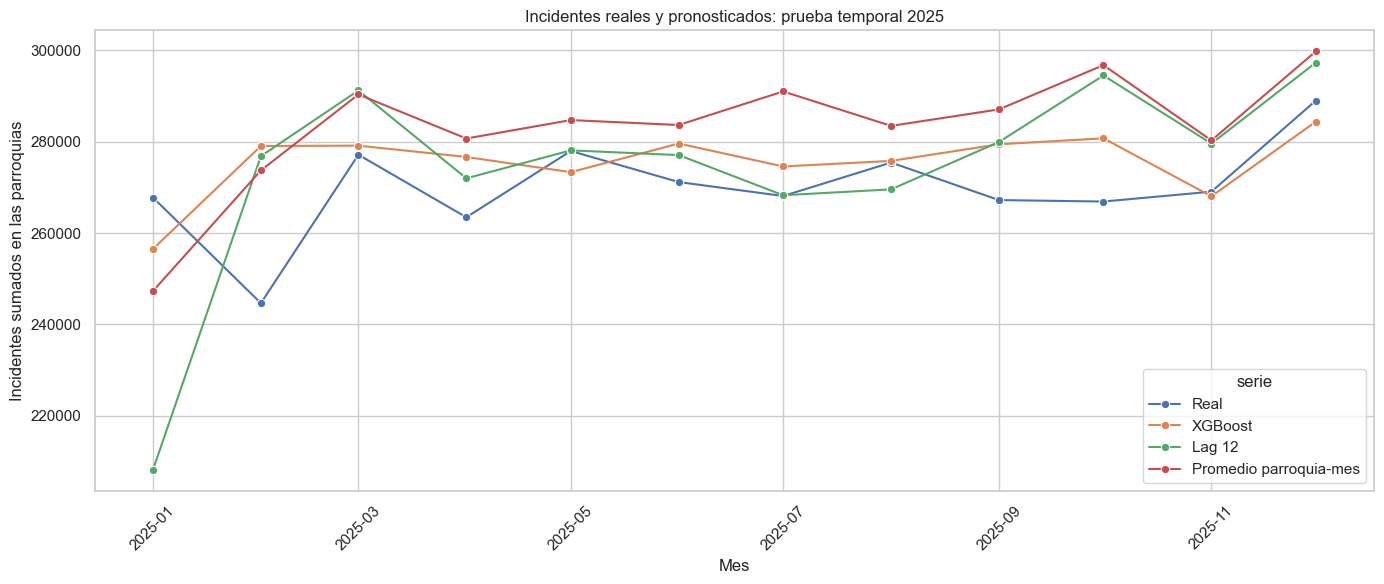

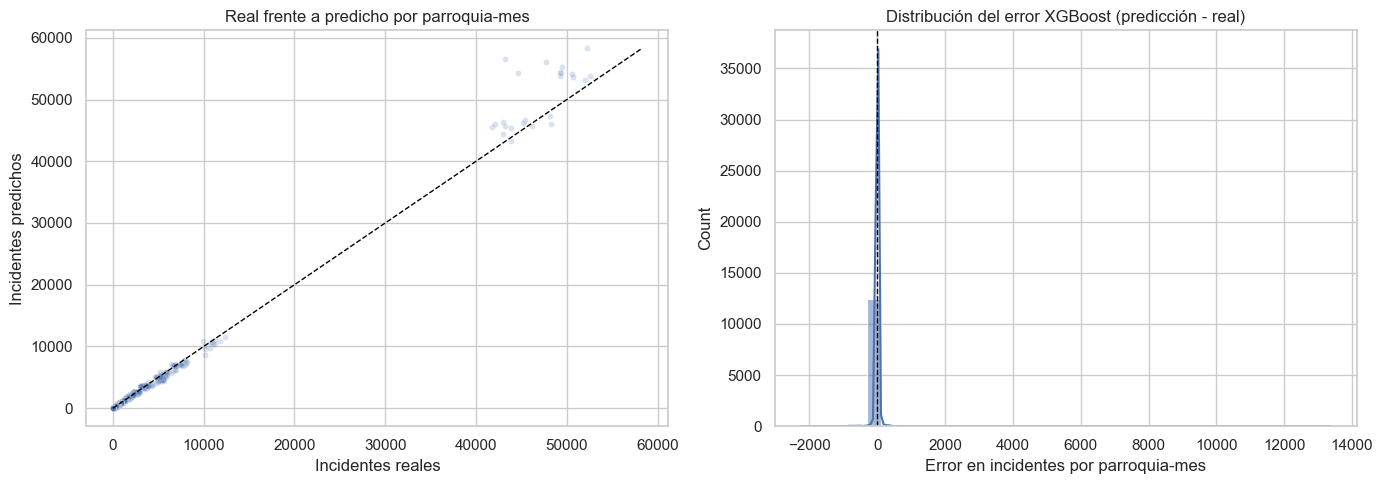

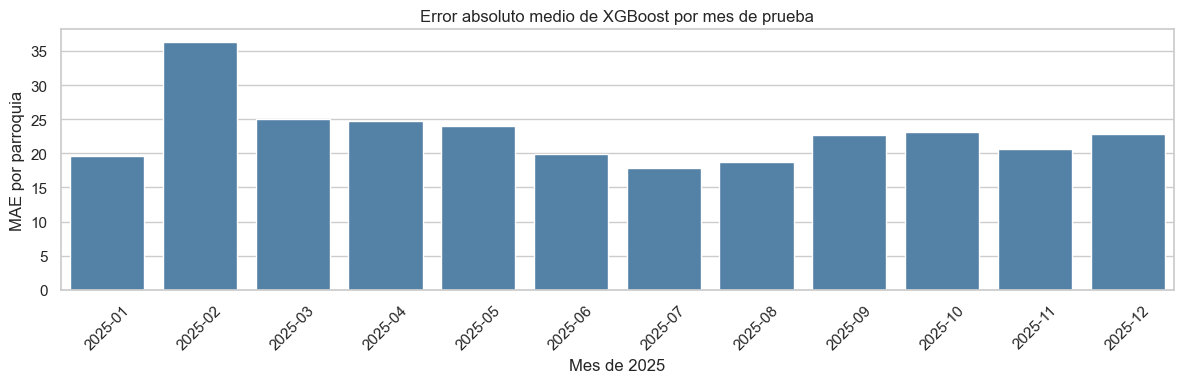

In [8]:
# Comparamos los conteos reales y estimados agregados a nivel nacional por mes.
monthly_plot = monthly_comparison.melt(
    id_vars='period',
    value_vars=['incidentes_reales', 'xgboost', 'lag_12', 'promedio_historico'],
    var_name='serie',
    value_name='incidentes',
)
series_labels = {
    'incidentes_reales': 'Real',
    'xgboost': 'XGBoost',
    'lag_12': 'Lag 12',
    'promedio_historico': 'Promedio parroquia-mes',
}
monthly_plot['serie'] = monthly_plot['serie'].map(series_labels)
plt.figure(figsize=(14, 6))
monthly_plot['plot_date'] = monthly_plot['period'].dt.to_timestamp()
sns.lineplot(data=monthly_plot, x='plot_date', y='incidentes', hue='serie', marker='o')
plt.title('Incidentes reales y pronosticados: prueba temporal 2025')
plt.xlabel('Mes')
plt.ylabel('Incidentes sumados en las parroquias')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Revisamos calibración y dispersión de errores para el modelo XGBoost.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=test_scored, x='target_count', y='XGBoost', alpha=0.2, s=18, ax=axes[0])
max_value = max(test_scored['target_count'].max(), test_scored['XGBoost'].max())
axes[0].plot([0, max_value], [0, max_value], color='black', linestyle='--', linewidth=1)
axes[0].set_title('Real frente a predicho por parroquia-mes')
axes[0].set_xlabel('Incidentes reales')
axes[0].set_ylabel('Incidentes predichos')

test_scored['residual_xgboost'] = test_scored['XGBoost'] - test_scored['target_count']
sns.histplot(test_scored['residual_xgboost'], bins=40, kde=True, ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1].set_title('Distribución del error XGBoost (predicción - real)')
axes[1].set_xlabel('Error en incidentes por parroquia-mes')
plt.tight_layout()
plt.show()

# Mostramos el error absoluto medio por mes para detectar meses más difíciles.
test_scored['absolute_error_xgboost'] = test_scored['residual_xgboost'].abs()
monthly_error = test_scored.groupby('period', observed=True)['absolute_error_xgboost'].mean().rename('MAE').reset_index()
plt.figure(figsize=(12, 4))
sns.barplot(data=monthly_error, x='period', y='MAE', color='steelblue')
plt.title('Error absoluto medio de XGBoost por mes de prueba')
plt.xlabel('Mes de 2025')
plt.ylabel('MAE por parroquia')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 9. Errores territoriales e importancia de variables

Los rankings siguientes describen concentraciones de reportes y errores observados en la prueba; no son una clasificación definitiva de peligrosidad. La importancia de XGBoost refleja asociaciones predictivas del modelo, no causalidad ni el efecto de modificar una variable.

,provincia,Canton,Parroquia,incidentes_reales_2025,incidentes_predichos_2025,MAE
0,GUAYAS,GUAYAQUIL,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",590963.0,658098.937500,5594.660156
1,PICHINCHA,QUITO,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",533870.0,548602.437500,1899.426147
2,AZUAY,CUENCA,"CUENCA, CABECERA CANTONAL Y CAPITAL PROVINCIAL.",130185.0,124320.125000,652.842468
3,SANTO DOMINGO DE LOS TSACHILAS,SANTO DOMINGO,"SANTO DOMINGO DE LOS COLORADOS, CABECERA CANTO...",91251.0,85660.664062,518.100159
4,TUNGURAHUA,AMBATO,"AMBATO, CABECERA CANTONAL Y CAPITAL PROVINCIAL",82620.0,83192.617188,241.176147
5,IMBABURA,IBARRA,"SAN MIGUEL DE IBARRA, CABECERA CANTONAL Y CAPI...",70424.0,68472.328125,357.186035
6,CHIMBORAZO,RIOBAMBA,"RIOBAMBA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",62482.0,60096.062500,252.836472
7,LOJA,LOJA,"LOJA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",61598.0,59766.121094,319.794525
8,EL ORO,MACHALA,"MACHALA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",63535.0,54090.054688,787.078796
9,PICHINCHA,QUITO,CALDERÓN (CARAPUNGO),46810.0,44829.484375,274.464264


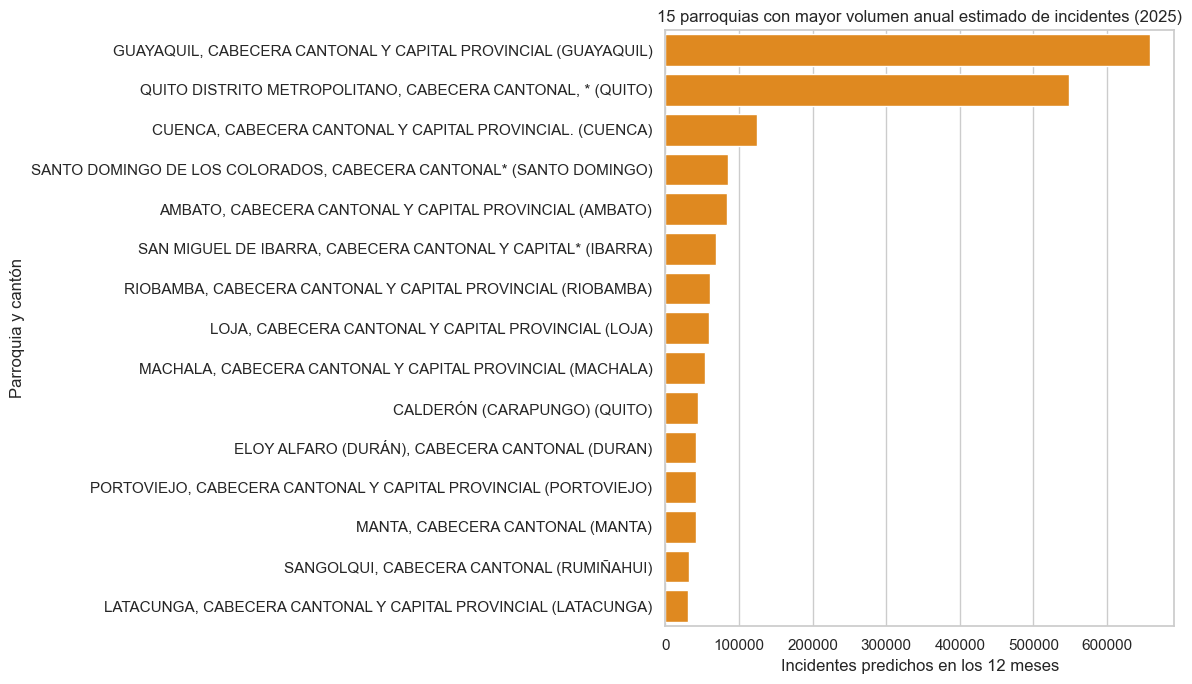

,variable,importancia
0,mean_previous_3,0.301473
1,lag_1,0.136327
2,lag_3,0.109722
3,mean_previous_12,0.104856
4,"Parroquia_CUENCA, CABECERA CANTONAL Y CAPITAL ...",0.076727
5,lag_12,0.074939
6,Canton_CUENCA,0.047321
7,provincia_AZUAY,0.039877
8,Canton_SANTO DOMINGO,0.030348
9,provincia_SANTO DOMINGO DE LOS TSACHILAS,0.028905


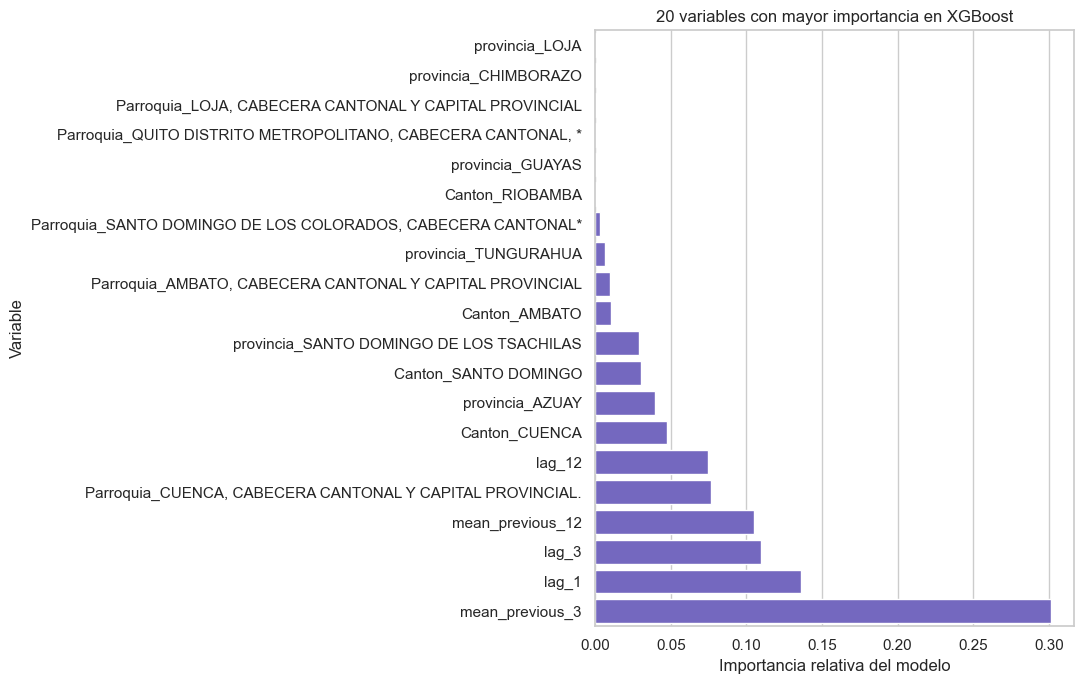

In [9]:
# Resumimos predicciones y errores por parroquia durante el año de prueba.
location_results = (
    test_scored.groupby(GEO_COLUMNS, as_index=False, observed=True)
    .agg(
        incidentes_reales_2025=('target_count', 'sum'),
        incidentes_predichos_2025=('XGBoost', 'sum'),
        MAE=('absolute_error_xgboost', 'mean'),
    )
)
display(location_results.sort_values('incidentes_predichos_2025', ascending=False).head(20).reset_index(drop=True))

# Graficamos las parroquias con mayor volumen estimado por XGBoost en los meses de prueba.
top_predicted_locations = location_results.nlargest(15, 'incidentes_predichos_2025').copy()
top_predicted_locations['ubicacion'] = (
    top_predicted_locations['Parroquia'].astype(str) + ' (' + top_predicted_locations['Canton'].astype(str) + ')'
)
plt.figure(figsize=(12, 7))
sns.barplot(data=top_predicted_locations, x='incidentes_predichos_2025', y='ubicacion', color='darkorange')
plt.title('15 parroquias con mayor volumen anual estimado de incidentes (2025)')
plt.xlabel('Incidentes predichos en los 12 meses')
plt.ylabel('Parroquia y cantón')
plt.tight_layout()
plt.show()

# Recuperamos los nombres de las variables luego de la codificación geográfica.
feature_names = preprocessor_final.get_feature_names_out()
feature_importance = pd.DataFrame({
    'variable': feature_names,
    'importancia': xgb_model.feature_importances_,
}).sort_values('importancia', ascending=False)
display(feature_importance.head(20).reset_index(drop=True))

# Graficamos las variables más influyentes según la importancia interna de XGBoost.
top_features = feature_importance.head(20).sort_values('importancia')
plt.figure(figsize=(11, 7))
sns.barplot(data=top_features, x='importancia', y='variable', color='slateblue')
plt.title('20 variables con mayor importancia en XGBoost')
plt.xlabel('Importancia relativa del modelo')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

## 10. Interpretación sencilla de los resultados

El siguiente resumen se genera con las métricas calculadas al ejecutar el notebook. MAE indica el error absoluto típico en incidentes por parroquia-mes; WAPE expresa el error absoluto total como porcentaje del volumen observado; RMSE penaliza más los errores grandes. Se considera mejor el modelo con menor MAE, pero se debe verificar también WAPE, el error por mes y los patrones territoriales.

In [10]:
# Identificamos el método con menor MAE y comparamos XGBoost con la mejor referencia simple.
best_method = metrics_table['MAE'].idxmin()
baseline_names = [name for name in prediction_columns if name != 'XGBoost']
best_baseline = metrics_table.loc[baseline_names, 'MAE'].idxmin()
baseline_mae = metrics_table.loc[best_baseline, 'MAE']
xgb_mae = metrics_table.loc['XGBoost', 'MAE']
mae_change_pct = 100 * (baseline_mae - xgb_mae) / max(baseline_mae, 1e-9)

# Generamos una explicación sencilla basada en los resultados efectivamente obtenidos.
if best_method == 'XGBoost' and mae_change_pct > 0:
    model_message = f"XGBoost obtuvo el menor MAE ({xgb_mae:.2f}) y redujo el error un {mae_change_pct:.1f}% frente a la mejor referencia ({best_baseline})."
elif best_method == 'XGBoost':
    model_message = f"XGBoost obtuvo el menor MAE ({xgb_mae:.2f}); sin embargo, la comparación porcentual con la referencia seleccionada requiere revisar la tabla de métricas."
else:
    model_message = f"La referencia **{best_method}** obtuvo un menor MAE ({metrics_table.loc[best_method, 'MAE']:.2f}) que XGBoost ({xgb_mae:.2f}); la complejidad adicional de XGBoost no mejoró el error absoluto en esta prueba."

# Presentamos las conclusiones principales sin inventar resultados antes de ejecutar las celdas.
observed_peak = monthly_comparison.loc[monthly_comparison['incidentes_reales'].idxmax()]
forecast_peak = monthly_comparison.loc[monthly_comparison['xgboost'].idxmax()]
display(Markdown(
    f"### Lectura automática\n\n"
    f"- **Período de prueba:** 2025, doce meses completos; la evaluación es por parroquia-mes.\n"
    f"- **Mejor MAE:** {best_method} ({metrics_table.loc[best_method, 'MAE']:.2f} incidentes por parroquia-mes).\n"
    f"- **Comparación principal:** {model_message}\n"
    f"- **WAPE de XGBoost:** {metrics_table.loc['XGBoost', 'WAPE (%)']:.2f}%. Este valor se calcula sobre los incidentes agregados, no como error porcentual de cada parroquia.\n"
    f'- **Mes de mayor volumen observado en la prueba:** {observed_peak["period"]} ({observed_peak["incidentes_reales"]:,.0f} reportes).\n'
    f'- **Mes de mayor volumen estimado por XGBoost:** {forecast_peak["period"]} ({forecast_peak["xgboost"]:,.0f} reportes).\n\n'
    "Un buen total nacional no garantiza buena predicción en cada parroquia. Revise el error mensual, los residuales, la tabla comparativa y las limitaciones de cobertura antes de emplear estas estimaciones en decisiones operativas."
))

### Lectura automática

- **Período de prueba:** 2025, doce meses completos; la evaluación es por parroquia-mes.
- **Mejor MAE:** XGBoost (22.94 incidentes por parroquia-mes).
- **Comparación principal:** XGBoost obtuvo el menor MAE (22.94) y redujo el error un 29.7% frente a la mejor referencia (Lag 12 (mismo mes año previo)).
- **WAPE de XGBoost:** 8.95%. Este valor se calcula sobre los incidentes agregados, no como error porcentual de cada parroquia.
- **Mes de mayor volumen observado en la prueba:** 2025-12 (289,009 reportes).
- **Mes de mayor volumen estimado por XGBoost:** 2025-12 (284,400 reportes).

Un buen total nacional no garantiza buena predicción en cada parroquia. Revise el error mensual, los residuales, la tabla comparativa y las limitaciones de cobertura antes de emplear estas estimaciones en decisiones operativas.

## 11. Conclusiones generales y uso responsable

1. El modelo estima **conteos reportados** por parroquia y mes. Para afirmar riesgo para turistas se necesitan denominadores de exposición (por ejemplo, población o flujo turístico), validación de calidad y análisis del subregistro.
2. La división temporal evita mezclar observaciones futuras con el entrenamiento. El resultado principal corresponde a 2025, año completo; 2021 y 2026 son parciales y no se comparan como años completos.
3. Use las métricas de parroquia-mes y los errores por período junto con los totales nacionales. Si XGBoost no supera referencias simples de forma consistente, prefiera la alternativa más sencilla hasta contar con datos o variables adicionales.
4. Los rezagos de 2025 presuponen que los conteos reales del mes anterior ya están disponibles; por ello, la evaluación representa actualización mensual de un pronóstico, no una predicción emitida de una sola vez para todo el año.
5. Las variables de importancia no son causas. No publique rankings como “zonas más peligrosas” sin normalizar por exposición, validar con autoridades y comunicar incertidumbre y limitaciones.

**Conclusión final:** este experimento permite comprobar si XGBoost aporta valor predictivo frente a baselines temporales para anticipar el volumen mensual de incidentes reportados. La decisión de adopción debe basarse en la tabla y los gráficos generados al ejecutar todas las celdas y en una validación posterior con datos actualizados.